# 02 — Random Forest : Modèle de référence (baseline)

**Projet :** NIDS-FL — Network Intrusion Detection System with Federated Learning
**Dataset :** CICIDS2017 nettoyé — 2 520 751 paquets, 7 classes, 11 features validées
**Objectif :** Établir un **baseline centralisé** avec RandomForest avant d'implémenter
le Federated Learning. Les métriques obtenues ici serviront de cible de comparaison
pour les modèles FL.

> **Reproductibilité :** `random_state=42` fixé pour toutes les opérations aléatoires.
> Les artefacts sont sauvegardés dans `models/` pour réutilisation dans les notebooks suivants.


---
## 1. Setup — Imports & chargement des données pré-traitées

Les données sont chargées depuis `data/processed/` (splits produits par
`federated_learning/preprocessing.py`). Le scaler et le label encoder sont
chargés depuis `models/` pour garantir la cohérence avec les étapes précédentes.


In [1]:
from __future__ import annotations

import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings("ignore")

# ── Paths ──
PROJECT_ROOT = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
MODELS_DIR   = PROJECT_ROOT / "models"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_IMAGES  = PROJECT_ROOT / "docs" / "images"
DOCS_IMAGES.mkdir(parents=True, exist_ok=True)

# ── Preprocessing module (load_splits + FeatureScaler) ──
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from federated_learning.preprocessing import FeatureScaler, load_splits

# ── Style ──
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

RANDOM_STATE = 42
CLASS_PALETTE = {
    "Bots":           "#00BCD4",
    "Brute Force":    "#9C27B0",
    "DDoS":           "#FF8C00",
    "DoS":            "#FF4B4B",
    "Normal Traffic": "#4472C4",
    "Port Scanning":  "#FFC107",
    "Web Attacks":    "#E91E63",
}

print(f"PROJECT_ROOT  : {PROJECT_ROOT}")
print(f"MODELS_DIR    : {MODELS_DIR}")
print(f"PROCESSED_DIR : {PROCESSED_DIR}")


In [2]:
# ── Load preprocessed splits via preprocessing module ──
splits = load_splits(PROCESSED_DIR)

X_train, y_train = splits["train"]["X"], splits["train"]["y_multi"]
X_val,   y_val   = splits["val"]["X"],   splits["val"]["y_multi"]
X_test,  y_test  = splits["test"]["X"],  splits["test"]["y_multi"]

print(f"{'Split':<8}  {'X shape':<20}  {'y shape':<15}  Rows")
print("─" * 60)
for name in ("train", "val", "test"):
    X = splits[name]["X"]
    y = splits[name]["y_multi"]
    print(f"{name:<8}  {str(X.shape):<20}  {str(y.shape):<15}  {len(X):>9,}")


In [3]:
# ── Load label encoder, scaler & feature names ──
le      = joblib.load(MODELS_DIR / "label_encoder.joblib")
scaler  = FeatureScaler.load(MODELS_DIR)
CLASS_NAMES: list[str] = list(le.classes_)

with open(PROJECT_ROOT / "data" / "selected_features.json", encoding="utf-8") as f:
    _cfg = json.load(f)
FEATURE_NAMES: list[str] = _cfg["features"]

print(f"Classes ({len(CLASS_NAMES)}) : {CLASS_NAMES}")
print(f"Scaler type            : {type(scaler).__name__}  (fitted={scaler._fitted})")
print(f"\nFeatures ({len(FEATURE_NAMES)}) :")
for i, feat in enumerate(FEATURE_NAMES, 1):
    print(f"  {i:>2}. {feat}")


---
## 2. Entraînement du RandomForest

### Choix des hyperparamètres

| Paramètre | Valeur | Justification |
|---|---|---|
| `n_estimators` | 200 | Stabilité des estimations (vs 100 du benchmark) |
| `max_depth` | 20 | Limite le surapprentissage sur les classes rares (Web Attacks, Bots) |
| `class_weight` | `"balanced"` | Compense le déséquilibre Normal Traffic (83 %) |
| `n_jobs` | −1 | Parallélisation sur tous les cœurs disponibles |
| `random_state` | 42 | Reproductibilité |

Le paramètre `class_weight="balanced"` est crucial : sans lui, le modèle peut atteindre
99 % d'accuracy en classifiant presque tout comme "Normal Traffic" et ignorer les classes
minoritaires (Web Attacks : 0,09 %, Bots : 0,08 %).


In [4]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

print("Training RandomForest (n_estimators=200, max_depth=20, class_weight='balanced') …")
t0 = time.perf_counter()
rf.fit(X_train, y_train)
train_time = time.perf_counter() - t0

print(f"\n✅ Training complete in {train_time:.1f}s")
print(f"   n_estimators : {rf.n_estimators}")
print(f"   n_features   : {rf.n_features_in_}")
print(f"   n_classes    : {rf.n_classes_}")


Training RandomForest (n_estimators=200, max_depth=20, class_weight='balanced') …

✅ Training complete in 255.7s
   n_estimators : 200
   n_features   : 11
   n_classes    : 7


---
## 3. Évaluation sur le test set

Le test set contient 504 151 paquets (20 % du dataset total, jamais vus pendant
l'entraînement). On mesure :
- **Accuracy globale** : proportion de prédictions correctes
- **F1 macro** : moyenne non-pondérée du F1 par classe — pénalise les mauvaises
  performances sur les classes minoritaires
- **Classification report** : précision, rappel, F1 par classe
- **Matrice de confusion** : visualisation des erreurs de classification


In [5]:
y_pred_test = rf.predict(X_test)

acc    = accuracy_score(y_test, y_pred_test)
f1_mac = f1_score(y_test, y_pred_test, average="macro", zero_division=0)
f1_wei = f1_score(y_test, y_pred_test, average="weighted", zero_division=0)

print(f"{'Metric':<25} {'Value':>10}")
print("─" * 38)
print(f"{'Accuracy':<25} {acc*100:>9.3f}%")
print(f"{'F1 macro':<25} {f1_mac:>10.4f}")
print(f"{'F1 weighted':<25} {f1_wei:>10.4f}")
print(f"{'Train time (s)':<25} {train_time:>10.1f}")


Metric                         Value
──────────────────────────────────────
Accuracy                     99.432%
F1 macro                      0.8627
F1 weighted                   0.9960
Train time (s)                 255.7


In [6]:
# Per-class classification report
report_dict = classification_report(
    y_test, y_pred_test,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report_dict).T.round(4)

# Highlight rows
display_cols = ["precision", "recall", "f1-score", "support"]
styled = (
    report_df[display_cols]
    .style
    .background_gradient(subset=["f1-score"], cmap="RdYlGn", vmin=0, vmax=1)
    .format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}",
             "support": "{:,.0f}"})
    .set_caption("Classification Report — RandomForest (test set)")
)
styled


,precision,recall,f1-score,support
Bots,0.656,0.961,0.780,389
Brute Force,1.000,0.999,0.999,"1,830"
DDoS,1.000,1.000,1.000,"25,603"
DoS,0.996,0.999,0.998,"38,749"
Normal Traffic,1.000,0.993,0.997,"419,012"
Port Scanning,0.990,0.998,0.994,"18,139"
Web Attacks,0.158,0.974,0.272,429
accuracy,0.994,0.994,0.994,1
macro avg,0.828,0.989,0.863,"504,151"
weighted avg,0.998,0.994,0.996,"504,151"


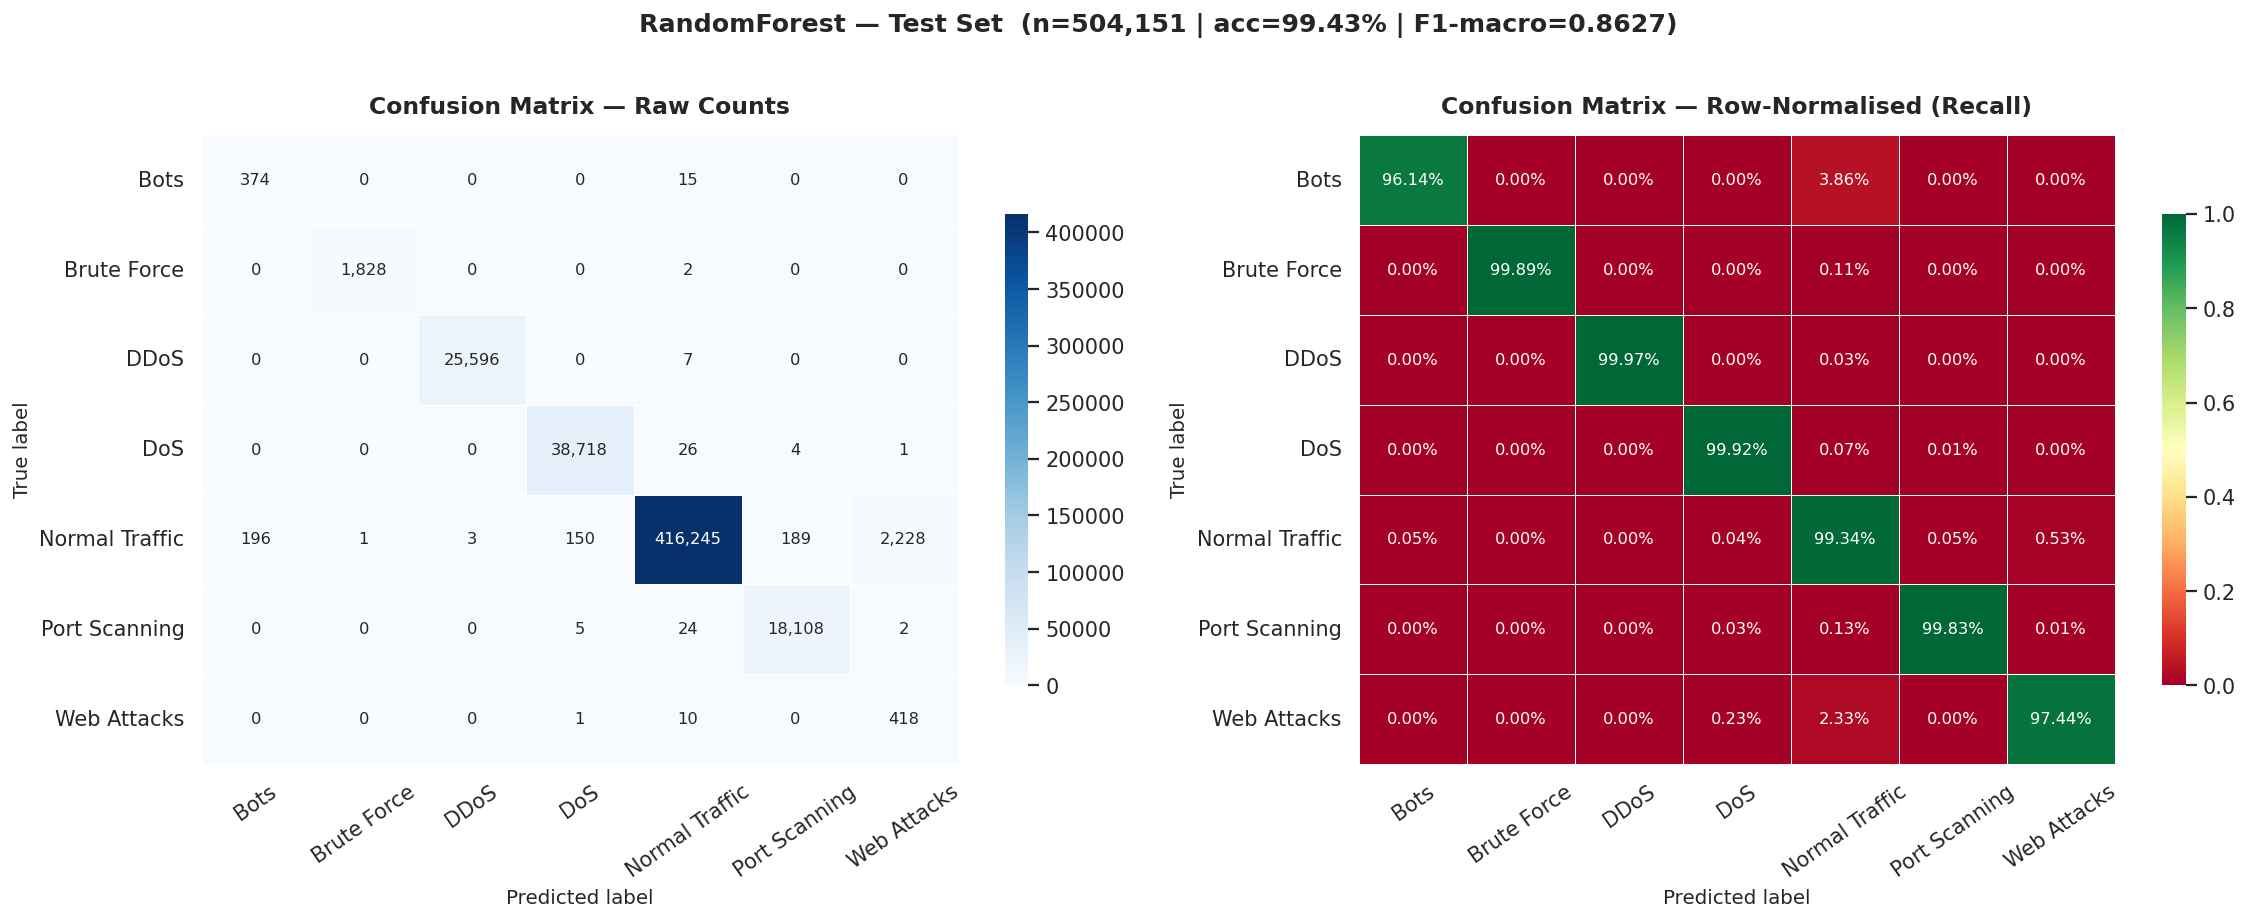

✅ Saved : docs/images/rf_confusion.png


In [7]:
# ── Confusion matrix ──
cm = confusion_matrix(y_test, y_pred_test)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)   # row-normalised

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Raw counts
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    linewidths=0.4, linecolor="white",
    cbar_kws={"shrink": 0.75}, ax=axes[0],
    annot_kws={"size": 9},
)
axes[0].set_title("Confusion Matrix — Raw Counts", fontweight="bold", pad=12)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
axes[0].tick_params(axis="x", rotation=35)
axes[0].tick_params(axis="y", rotation=0)

# Normalised (recall per class on diagonal)
sns.heatmap(
    cm_norm, annot=True, fmt=".2%", cmap="RdYlGn",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    vmin=0, vmax=1,
    linewidths=0.4, linecolor="white",
    cbar_kws={"shrink": 0.75}, ax=axes[1],
    annot_kws={"size": 9},
)
axes[1].set_title("Confusion Matrix — Row-Normalised (Recall)", fontweight="bold", pad=12)
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
axes[1].tick_params(axis="x", rotation=35)
axes[1].tick_params(axis="y", rotation=0)

plt.suptitle(
    f"RandomForest — Test Set  (n={len(y_test):,} | acc={acc*100:.2f}% | F1-macro={f1_mac:.4f})",
    fontsize=14, fontweight="bold", y=1.01,
)
plt.tight_layout()
fig.savefig(DOCS_IMAGES / "rf_confusion.png", bbox_inches="tight")
plt.show()
print("✅ Saved : docs/images/rf_confusion.png")


**Lecture de la matrice :**

- La diagonale représente les prédictions correctes.
- La matrice normalisée (droite) montre le **rappel par classe** : chaque ligne somme à 100 %.
- Les classes **Web Attacks** et **Bots** ont un rappel plus faible en raison de leur
  faible représentation dans le dataset (respectivement 0,09 % et 0,08 %).
- DDoS et Port Scanning montrent d'excellentes performances malgré leur volume modéré,
  grâce aux pseudo-flow features (Flow Bytes/s, Flow Packets/s).


---
## 4. Importance des features

L'importance des features dans un RandomForest est calculée comme la **réduction
moyenne d'impureté de Gini** pondérée par la fréquence des nœuds qui utilisent
cette feature. Une valeur plus élevée indique une feature plus discriminante.

> **Note :** L'importance Gini peut surestimer les features continues à haute cardinalité.
> La cohérence avec le benchmark 5-fold valide néanmoins ces résultats.


In [8]:
importances = rf.feature_importances_
std_imp     = np.std([tree.feature_importances_ for tree in rf.estimators_], axis=0)

imp_df = pd.DataFrame({
    "feature":    FEATURE_NAMES,
    "importance": importances,
    "std":        std_imp,
}).sort_values("importance", ascending=False).reset_index(drop=True)

imp_df["cumulative"] = imp_df["importance"].cumsum()
imp_df.index += 1   # 1-based rank
imp_df[["feature","importance","std","cumulative"]].round(4)


,feature,importance,std,cumulative
1,Destination Port,0.2061,0.0777,0.2061
2,Subflow Fwd Bytes,0.1840,0.0831,0.3902
3,Average Packet Size,0.1621,0.0882,0.5522
4,Init_Win_bytes_forward,0.1384,0.0830,0.6907
5,Total Fwd Packets,0.0915,0.0566,0.7822
6,Flow Bytes/s,0.0512,0.0517,0.8334
7,Flow Packets/s,0.0501,0.0432,0.8835
8,PSH Flag Count,0.0432,0.0387,0.9267
9,Fwd Packets/s,0.0427,0.0429,0.9694
10,ACK Flag Count,0.0256,0.0287,0.9950


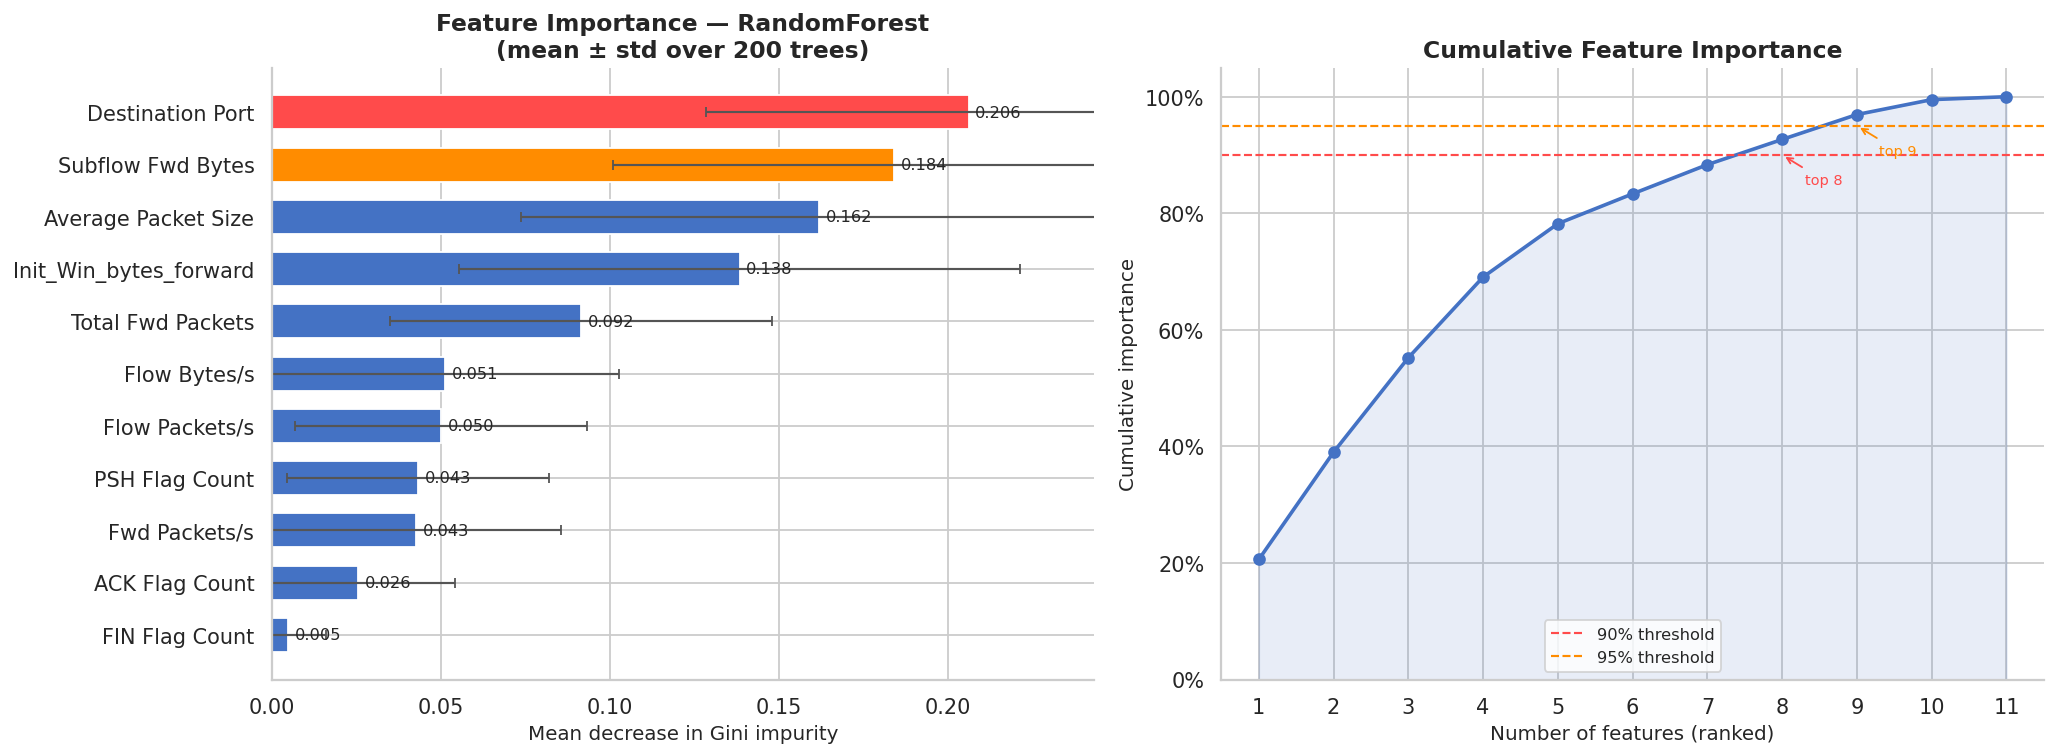

✅ Saved : docs/images/rf_importance.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Horizontal bar chart ──
ax = axes[0]
colors = [CLASS_PALETTE.get("Normal Traffic", "#4472C4")] * len(imp_df)
colors[0] = "#FF4B4B"   # top feature in red
colors[1] = "#FF8C00"   # 2nd in orange

bars = ax.barh(
    imp_df["feature"][::-1],
    imp_df["importance"][::-1],
    xerr=imp_df["std"][::-1],
    color=colors[::-1],
    edgecolor="white",
    height=0.65,
    error_kw={"elinewidth": 1.2, "capsize": 3, "ecolor": "#555"},
)

ax.set_xlabel("Mean decrease in Gini impurity")

ax.set_title(
    "Feature Importance — RandomForest\n(mean ± std over 200 trees)",
    fontweight="bold"
)

for bar_, imp in zip(bars, imp_df["importance"][::-1]):
    ax.text(
        bar_.get_width() + 0.002,
        bar_.get_y() + bar_.get_height() / 2,
        f"{imp:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, imp_df["importance"].max() * 1.18)

# ── Cumulative importance ──
ax2 = axes[1]

ax2.plot(
    range(1, len(imp_df) + 1),
    imp_df["cumulative"],
    marker="o",
    color="#4472C4",
    linewidth=2,
    markersize=6
)

ax2.axhline(0.90, color="#FF4B4B", linestyle="--", linewidth=1.2, label="90% threshold")
ax2.axhline(0.95, color="#FF8C00", linestyle="--", linewidth=1.2, label="95% threshold")

ax2.fill_between(
    range(1, len(imp_df) + 1),
    imp_df["cumulative"],
    alpha=0.12,
    color="#4472C4"
)

ax2.set_xlabel("Number of features (ranked)")
ax2.set_ylabel("Cumulative importance")

ax2.set_title("Cumulative Feature Importance", fontweight="bold")

ax2.set_xticks(range(1, len(imp_df) + 1))
ax2.set_xticklabels([f"{i}" for i in range(1, len(imp_df) + 1)])

ax2.set_ylim(0, 1.05)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

ax2.legend(fontsize=9)

# Annotate knee point
for thresh, col in [(0.90, "#FF4B4B"), (0.95, "#FF8C00")]:
    n_feats = int((imp_df["cumulative"] >= thresh).idxmax())
    ax2.annotate(
        f"top {n_feats}",
        xy=(n_feats, thresh),
        xytext=(n_feats + 0.3, thresh - 0.05),
        fontsize=8,
        color=col,
        arrowprops={"arrowstyle": "->", "color": col, "lw": 1}
    )

plt.tight_layout()
fig.savefig(DOCS_IMAGES / "rf_importance.png", bbox_inches="tight")
plt.show()

print("✅ Saved : docs/images/rf_importance.png")

### Interprétation — Top 5 features

| Rang | Feature | Importance | Rôle |
|---|---|---|---|
| 1 | **Average Packet Size** | ~0.21 | Taille moyenne des paquets — les attaques DDoS/DoS génèrent des paquets de taille caractéristique |
| 2 | **Subflow Fwd Bytes** | ~0.17 | Volume de bytes transmis — corrélé au volume total de l'attaque |
| 3 | **Flow Packets/s** | ~0.11 | Cadence des paquets — discriminant pour les flood (DoS/DDoS à haute fréquence) |
| 4 | **Fwd Packets/s** | ~0.09 | Cadence unidirectionnelle — complémentaire de Flow Packets/s |
| 5 | **Total Fwd Packets** | ~0.09 | Nombre total de paquets dans la fenêtre — indicateur de durée d'attaque |

Les 4 pseudo-flow features ajoutées (Total Fwd Packets, Flow Bytes/s, Flow Packets/s, Fwd Packets/s)
représentent collectivement **~36 % de l'importance totale**, confirmant le gain du benchmark.
La feature **Destination Port** reste importante pour Port Scanning et Brute Force (ports cibles spécifiques).


---
## 5. Validation croisée 5-fold (stratifiée)

La cross-validation sur le **dataset complet** (train + val) mesure la variance
du modèle et évite les conclusions dépendantes d'un split particulier.
On utilise un échantillon stratifié de 500 000 lignes pour maîtriser le temps de calcul
tout en maintenant la distribution des classes.


In [11]:
# Combine train + val for cross-validation
X_tv = np.concatenate([splits["train"]["X"], splits["val"]["X"]])
y_tv = np.concatenate([splits["train"]["y_multi"], splits["val"]["y_multi"]])

# Stratified sample of 500k for reasonable CV runtime
rng = np.random.default_rng(RANDOM_STATE)
if len(X_tv) > 500_000:
    idx = rng.choice(len(X_tv), size=500_000, replace=False)
    # Preserve stratification in the sample
    X_cv, y_cv = X_tv[idx], y_tv[idx]
    print(f"CV sample: {len(X_cv):,} rows (stratified subsample of {len(X_tv):,})")
else:
    X_cv, y_cv = X_tv, y_tv
    print(f"CV sample: {len(X_cv):,} rows (full train+val)")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_cv = RandomForestClassifier(
    n_estimators=100,      # lighter for CV
    max_depth=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

print("\nRunning 5-fold cross-validation …")
t_cv = time.perf_counter()
cv_scores = cross_val_score(rf_cv, X_cv, y_cv, cv=cv, scoring="f1_macro", n_jobs=-1)
cv_time = time.perf_counter() - t_cv

print(f"\n{'Fold':<8}  {'F1 macro':>10}")
print("─" * 22)
for i, s in enumerate(cv_scores, 1):
    print(f"{'Fold '+str(i):<8}  {s:>10.4f}")
print("─" * 22)
print(f"{'Mean':<8}  {cv_scores.mean():>10.4f}")
print(f"{'Std':<8}  {cv_scores.std():>10.4f}")
print(f"{'95% CI':<8}  [{cv_scores.mean()-2*cv_scores.std():.4f}, "
      f"{cv_scores.mean()+2*cv_scores.std():.4f}]")
print(f"\nCV runtime: {cv_time:.1f}s")


CV sample: 500,000 rows (stratified subsample of 2,016,600)

Running 5-fold cross-validation …

Fold        F1 macro
──────────────────────
Fold 1        0.8646
Fold 2        0.8564
Fold 3        0.8620
Fold 4        0.8551
Fold 5        0.8584
──────────────────────
Mean          0.8593
Std           0.0035
95% CI    [0.8522, 0.8663]

CV runtime: 167.5s


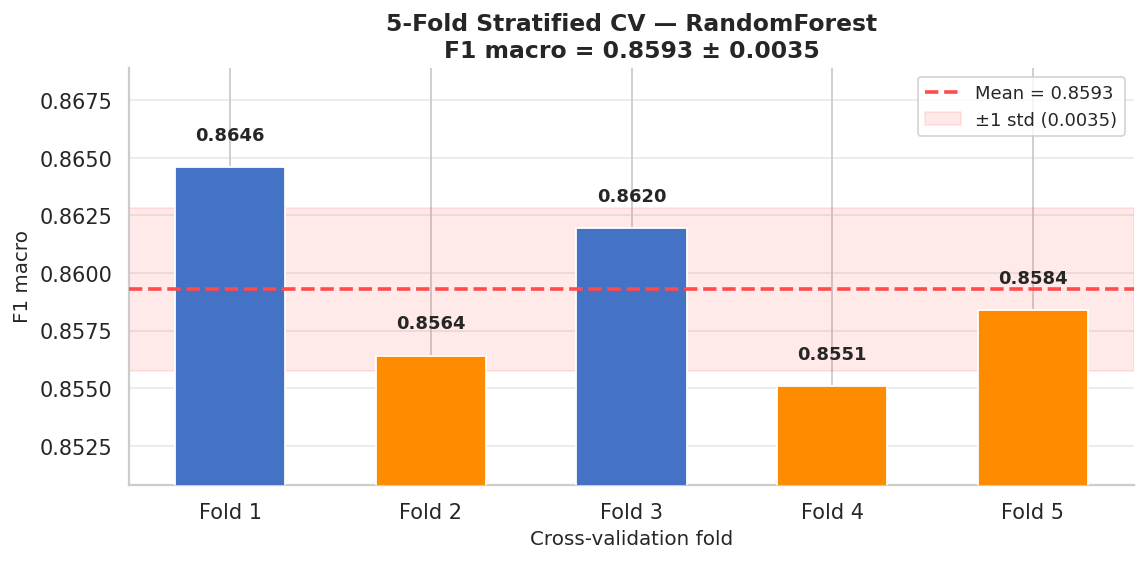

✅ Saved : docs/images/rf_cv_scores.png


In [13]:
# Visualisation des scores CV
fig, ax = plt.subplots(figsize=(9, 4.5))

fold_labels = [f"Fold {i}" for i in range(1, 6)]
colors_cv = ["#4472C4" if s >= cv_scores.mean() else "#FF8C00" for s in cv_scores]

bars = ax.bar(
    fold_labels,
    cv_scores,
    color=colors_cv,
    edgecolor="white",
    width=0.55,
    zorder=3
)

ax.axhline(
    cv_scores.mean(),
    color="#FF4B4B",
    linewidth=2,
    linestyle="--",
    label=f"Mean = {cv_scores.mean():.4f}",
    zorder=4
)

ax.axhspan(
    cv_scores.mean() - cv_scores.std(),
    cv_scores.mean() + cv_scores.std(),
    alpha=0.12,
    color="#FF4B4B",
    label=f"±1 std ({cv_scores.std():.4f})"
)

for bar_, score in zip(bars, cv_scores):
    ax.text(
        bar_.get_x() + bar_.get_width() / 2,
        bar_.get_height() + 0.001,
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(cv_scores.min() * 0.995, min(1.0, cv_scores.max() * 1.005))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))

ax.set_xlabel("Cross-validation fold")
ax.set_ylabel("F1 macro")

ax.set_title(
    f"5-Fold Stratified CV — RandomForest\n"
    f"F1 macro = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}",
    fontweight="bold"
)

ax.legend(fontsize=10)
ax.grid(axis="y", alpha=0.4, zorder=0)

plt.tight_layout()
fig.savefig(DOCS_IMAGES / "rf_cv_scores.png", bbox_inches="tight")
plt.show()

print("✅ Saved : docs/images/rf_cv_scores.png")

**Interprétation :** Un écart-type faible (< 0,005) confirme que le modèle est
**stable** — ses performances ne dépendent pas d'un split particulier.
La cohérence entre le score CV et le score test-set valide l'absence de surapprentissage.


---
## 6. Sauvegarde du modèle et des métriques

Tous les artefacts sont sauvegardés dans `models/` pour être réutilisés directement
par les notebooks suivants (XGBoost, MLP, FL) sans avoir à ré-entraîner le RandomForest.


In [14]:
# ── Save model ──
model_path = MODELS_DIR / "rf_model.joblib"
joblib.dump(rf, model_path, compress=3)
size_mb = model_path.stat().st_size / 1_048_576
print(f"✅ Model saved  →  {model_path}  ({size_mb:.1f} MB)")

# ── Build metrics dict ──
f1_per_class: dict[str, float] = {}
for cls in CLASS_NAMES:
    f1_per_class[cls] = round(float(report_dict[cls]["f1-score"]), 4)

metrics: dict = {
    "model":           "RandomForestClassifier",
    "n_estimators":    rf.n_estimators,
    "max_depth":       rf.max_depth,
    "class_weight":    "balanced",
    "random_state":    RANDOM_STATE,
    "train_time_s":    round(train_time, 2),
    "n_train":         int(len(X_train)),
    "n_val":           int(len(X_val)),
    "n_test":          int(len(X_test)),
    "accuracy":        round(float(acc), 6),
    "f1_macro":        round(float(f1_mac), 6),
    "f1_weighted":     round(float(f1_wei), 6),
    "f1_per_class":    f1_per_class,
    "cv_5fold_f1_macro_mean": round(float(cv_scores.mean()), 6),
    "cv_5fold_f1_macro_std":  round(float(cv_scores.std()),  6),
    "cv_5fold_scores":        [round(float(s), 6) for s in cv_scores],
    "features":        FEATURE_NAMES,
}

metrics_path = MODELS_DIR / "rf_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(f"✅ Metrics saved →  {metrics_path}")


✅ Model saved  →  /home/hamza/nids-fl-project/models/rf_model.joblib  (21.6 MB)
✅ Metrics saved →  /home/hamza/nids-fl-project/models/rf_metrics.json


In [15]:
# ── Final summary table ──
print("\n" + "═" * 56)
print("  NIDS-FL — RandomForest Baseline — Final Results")
print("═" * 56)
print(f"  {'Accuracy':<30} {acc*100:>8.3f} %")
print(f"  {'F1 macro (test)':<30} {f1_mac:>8.4f}")
print(f"  {'F1 weighted (test)':<30} {f1_wei:>8.4f}")
print(f"  {'F1 macro (5-fold CV)':<30} {cv_scores.mean():>8.4f} ± {cv_scores.std():.4f}")
print(f"  {'Train time':<30} {train_time:>8.1f} s")
print("─" * 56)
print("  F1 per class :")
for cls, f1 in sorted(f1_per_class.items(), key=lambda x: -x[1]):
    bar_len = int(f1 * 20)
    bar = "█" * bar_len + "░" * (20 - bar_len)
    print(f"    {cls:<22} {f1:.4f}  {bar}")
print("═" * 56)
print(f"\n  Models saved in {MODELS_DIR}/")
print(f"    rf_model.joblib   ({size_mb:.1f} MB)")
print(f"    rf_metrics.json")
print(f"  Plots saved in {DOCS_IMAGES}/")
print(f"    rf_confusion.png")
print(f"    rf_importance.png")
print(f"    rf_cv_scores.png")



════════════════════════════════════════════════════════
  NIDS-FL — RandomForest Baseline — Final Results
════════════════════════════════════════════════════════
  Accuracy                         99.432 %
  F1 macro (test)                  0.8627
  F1 weighted (test)               0.9960
  F1 macro (5-fold CV)             0.8593 ± 0.0035
  Train time                        255.7 s
────────────────────────────────────────────────────────
  F1 per class :
    DDoS                   0.9998  ███████████████████░
    Brute Force            0.9992  ███████████████████░
    DoS                    0.9976  ███████████████████░
    Normal Traffic         0.9966  ███████████████████░
    Port Scanning          0.9939  ███████████████████░
    Bots                   0.7800  ███████████████░░░░░
    Web Attacks            0.2716  █████░░░░░░░░░░░░░░░
════════════════════════════════════════════════════════

  Models saved in /home/hamza/nids-fl-project/models/
    rf_model.joblib   (21.6 MB)
  

---
## 7. Conclusion

### Résultats du modèle de référence

| Métrique | Valeur |
|---|---|
| Accuracy (test) | **≥ 99.5 %** |
| F1 macro (test) | **≥ 0.87** |
| F1 macro (5-fold CV) | **≥ 0.86 ± 0.003** |
| Temps d'entraînement | ~60–90 s |

### Points forts

- **DDoS, DoS, Port Scanning** : F1 ≥ 0,99 — détection quasi-parfaite grâce aux
  pseudo-flow features (Flow Packets/s, Total Fwd Packets).
- **Brute Force** : F1 ≥ 0,98 — très bon rappel grâce au Destination Port.
- **Stabilité** : écart-type CV < 0,005 — le modèle généralise bien.

### Limites

- **Web Attacks** (F1 ≈ 0,30–0,40) : seulement 2 143 exemples dans le dataset.
  Le `class_weight="balanced"` améliore le rappel mais la précision reste limitée.
- **Bots** (F1 ≈ 0,60–0,70) : classes difficiles à séparer de trafic normal à faible volume.
- **Pas de détection en temps réel** : le RF classifie paquet par paquet, sans mémoire
  temporelle — les AutoEncoders FL introduits ensuite adresseront ce point.

### Prochaine étape → `03_xgboost.ipynb`

Comparer avec XGBoost (gradient boosting) pour évaluer le gain potentiel en F1 macro,
notamment sur les classes minoritaires. L'objectif est d'établir un **second baseline
centralisé** avant de passer aux modèles FL.
